# 02 - Tiền xử lý, đặc trưng, lựa chọn đặc trưng, baseline (SV3)

Nội dung: (1) pipeline tiền xử lý; (2) feature engineering; (3) lựa chọn đặc trưng; (4) baseline DummyClassifier (mốc cho RQ1).

Mọi con số dưới đây tính trên **tập train** (CV 5-fold). Tập test không được dùng.

In [1]:
import os, sys, warnings
from pathlib import Path
os.chdir(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())
sys.path.insert(0, os.getcwd())
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src import config
from src.data import get_train_test
from src.evaluate import cross_validate_model, get_cv
from src.preprocessing import build_pipeline, build_preprocessor, get_feature_names, get_column_groups

sns.set_theme(style="whitegrid")
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
X_train, X_test, y_train, y_test = get_train_test("C")   # tập test KHÔNG dùng trong notebook này
print(X_train.shape, y_train.value_counts(normalize=True).round(3).to_dict())

(3539, 36) {'Graduate': 0.499, 'Dropout': 0.321, 'Enrolled': 0.179}


## 1. Pipeline tiền xử lý

- 10 biến phân loại mã số không thứ tự -> One-Hot (`handle_unknown="ignore"`), mã xuất hiện < 20 mẫu gộp thành nhóm *infrequent* ("Other").
- 7 biến nhị phân giữ nguyên.
- Biến số: `StandardScaler` chỉ khi `scale=True` (LR/SVM); cây không cần.

In [2]:
rows = []
for fs in "ABC":
    cat, binr, num = get_column_groups(fs)
    Xa, _, ya, _ = get_train_test(fs)
    pre = build_preprocessor(fs, scale=True).fit(Xa, ya)
    out = pre.transform(Xa)
    rows.append({"feature_set": fs, "n_cot_goc": Xa.shape[1], "phan_loai": len(cat), "nhi_phan": len(binr),
                 "so(+moi)": len(num), "n_cot_sau_xu_ly": out.shape[1], "co_NaN": bool(out.isna().any().any())})
pd.DataFrame(rows)

,feature_set,n_cot_goc,phan_loai,nhi_phan,so(+moi),n_cot_sau_xu_ly,co_NaN
0,A,24,10,7,7,108,False
1,B,30,10,7,14,115,False
2,C,36,10,7,22,123,False


In [3]:
# Mức độ gộp "Other": bao nhiêu mã hiếm bị gộp trên tập train
pre = build_preprocessor("C", scale=False).fit(X_train, y_train)
ohe = pre.named_steps["encode"].named_transformers_["cat"]
cat_cols = get_column_groups("C")[0]
tong = []
for col, cats, inf in zip(cat_cols, ohe.categories_, ohe.infrequent_categories_):
    tong.append({"bien": col, "so_ma": len(cats), "so_ma_gop_Other": 0 if inf is None else len(inf)})
pd.DataFrame(tong)

,bien,so_ma,so_ma_gop_Other
0,Marital status,6,3
1,Application mode,18,6
2,Course,17,1
3,Daytime/evening attendance,2,0
4,Previous qualification,17,9
5,Nationality,19,17
6,Mother's qualification,28,19
7,Father's qualification,32,23
8,Mother's occupation,31,19
9,Father's occupation,41,29


## 2. Feature engineering (`src/features.py`)

Ba đặc trưng mới, tính trong transformer của Pipeline:

- `Pass rate 1st sem` = approved / enrolled (kỳ 1)
- `Pass rate 2nd sem` = approved / enrolled (kỳ 2)
- `Grade change 2nd vs 1st` = điểm TB kỳ 2 - điểm TB kỳ 1

Chia cho 0 (không đăng ký môn nào) được xử lý thành 0.

          Pass rate 1st sem  Pass rate 2nd sem  Grade change 2nd vs 1st
Target                                                                 
Dropout               0.383              0.291                   -1.371
Enrolled              0.689              0.653                    0.009
Graduate              0.901              0.900                    0.041


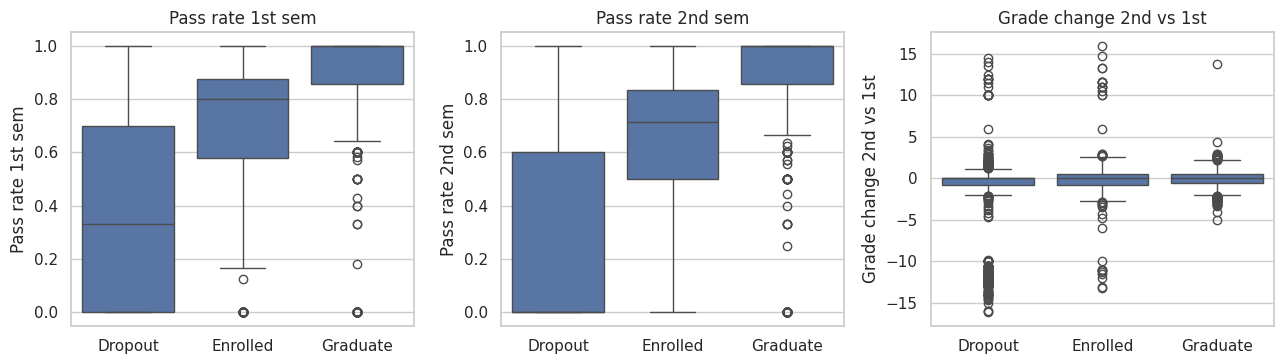

In [4]:
from src.features import CurricularFeatures, engineered_columns
newf = CurricularFeatures("C").fit_transform(X_train)[engineered_columns("C")]
d = newf.assign(Target=y_train.values)
print(d.groupby("Target").mean().round(3))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, c in zip(axes, engineered_columns("C")):
    sns.boxplot(data=d, x="Target", y=c, order=config.CLASSES, ax=ax)
    ax.set_title(c); ax.set_xlabel("")
fig.tight_layout(); fig.savefig(config.FIGURES_DIR / "02_new_features_by_target.png", dpi=200)

In [5]:
# Đóng góp của đặc trưng mới: CV Macro-F1 có / không có (cùng mô hình, cùng fold)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
rows = []
for af in (False, True):
    for name, est, sc in [("LogisticRegression", LogisticRegression(max_iter=3000), True),
                          ("DecisionTree(depth=5)", DecisionTreeClassifier(max_depth=5, random_state=42), False)]:
        r = cross_validate_model(build_pipeline(est, "C", sc, add_features=af), X_train, y_train,
                                 name=name, feature_set="C", log=False)
        rows.append({"model": name, "them_dac_trung_moi": af, "f1_macro_val": r["f1_macro_mean"],
                     "std": r["f1_macro_std"], "f1_macro_train": r["train_f1_macro_mean"]})
abl = pd.DataFrame(rows).round(4)
abl.to_csv(config.RESULTS_DIR / "features_ablation.csv", index=False)
abl

,model,them_dac_trung_moi,f1_macro_val,std,f1_macro_train
0,LogisticRegression,False,0.6998,0.0211,0.7439
1,DecisionTree(depth=5),False,0.6563,0.0180,0.7022
2,LogisticRegression,True,0.6983,0.0178,0.7451
3,DecisionTree(depth=5),True,0.6734,0.0355,0.7179


## 3. Lựa chọn đặc trưng

Ba góc nhìn: mutual information, hệ số L1 của LR, độ quan trọng RF. **Xếp hạng chỉ để khám phá** (fit trên train). Việc quyết định có loại đặc trưng hay không dựa trên CV Macro-F1 với bước chọn đặc trưng đặt *trong* Pipeline (không rò rỉ).

L1 (C=0.05): số đặc trưng có hệ số khác 0 ở ít nhất một lớp = 27 / 123


Giao top-15 của cả 3 phương pháp: ['Age at enrollment', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (evaluations)', 'Grade change 2nd vs 1st', 'Pass rate 2nd sem', 'Tuition fees up to date']


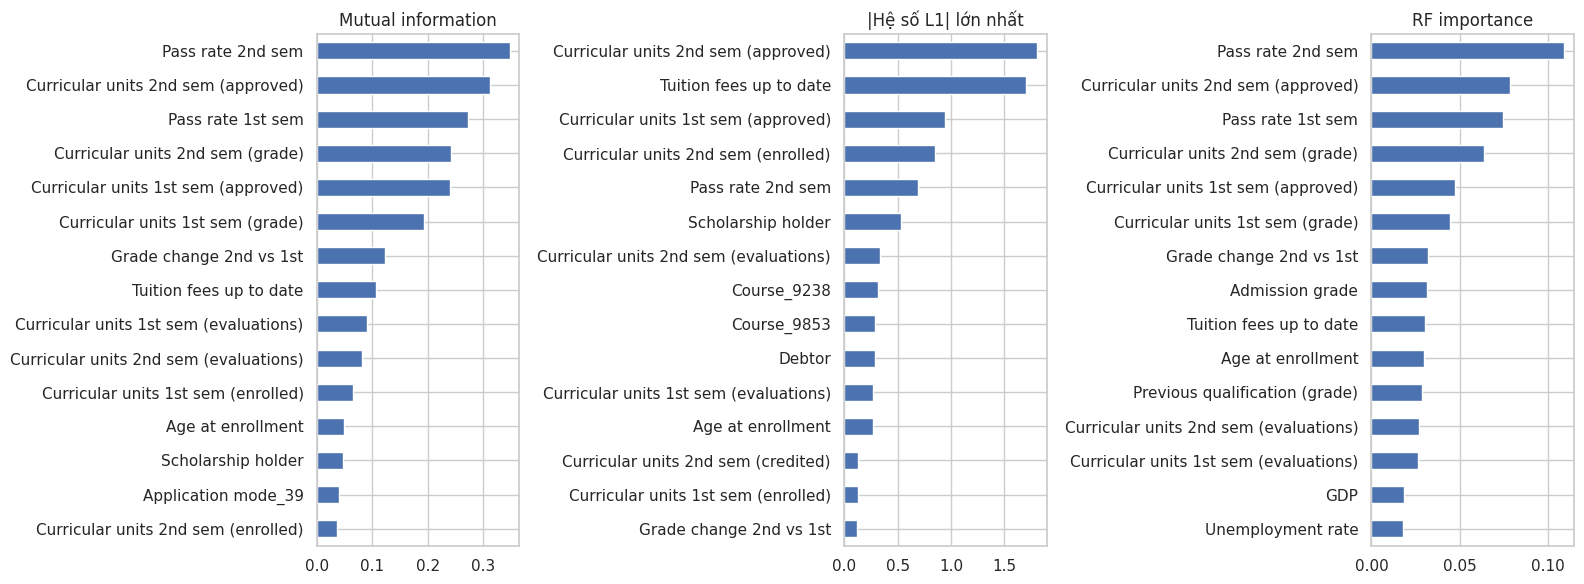

In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif

pre_s = build_preprocessor("C", scale=True).fit(X_train, y_train)
Xp = pre_s.transform(X_train); names = list(Xp.columns)

mi = pd.Series(mutual_info_classif(Xp, y_train, random_state=42), index=names).sort_values(ascending=False)
l1 = LogisticRegression(penalty="l1", C=0.05, solver="saga", max_iter=5000, random_state=42).fit(Xp, y_train)
l1_abs = pd.Series(np.abs(l1.coef_).max(axis=0), index=names).sort_values(ascending=False)
rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1).fit(Xp, y_train)
rf_imp = pd.Series(rf.feature_importances_, index=names).sort_values(ascending=False)

rank = pd.DataFrame({"MI": mi, "L1_max_abs_coef": l1_abs, "RF_importance": rf_imp}).loc[names]
rank.sort_values("MI", ascending=False).round(4).to_csv(config.RESULTS_DIR / "feature_selection_ranking.csv")
print("L1 (C=0.05): số đặc trưng có hệ số khác 0 ở ít nhất một lớp =", int((l1_abs > 0).sum()), "/", len(names))
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
for ax, (title, s) in zip(axes, [("Mutual information", mi), ("|Hệ số L1| lớn nhất", l1_abs), ("RF importance", rf_imp)]):
    s.head(15)[::-1].plot.barh(ax=ax); ax.set_title(title)
fig.tight_layout(); fig.savefig(config.FIGURES_DIR / "02_feature_selection_top15.png", dpi=200)
top = lambda s: set(s.head(15).index)
print("Giao top-15 của cả 3 phương pháp:", sorted(top(mi) & top(l1_abs) & top(rf_imp)))

In [7]:
# CV Macro-F1 khi giữ top-k đặc trưng theo MI (SelectKBest nằm trong Pipeline)
rows = []
n_all = Xp.shape[1]
for k in [20, 40, 60, 80, None]:
    r = cross_validate_model(build_pipeline(LogisticRegression(max_iter=3000), "C", True, select_k=k),
                             X_train, y_train, name="LR", feature_set="C", log=False)
    rows.append({"k": k or n_all, "f1_macro_val": r["f1_macro_mean"], "std": r["f1_macro_std"],
                 "f1_macro_train": r["train_f1_macro_mean"]})
sel = pd.DataFrame(rows).round(4)
sel.to_csv(config.RESULTS_DIR / "feature_selection_cv.csv", index=False)
sel

,k,f1_macro_val,std,f1_macro_train
0,20,0.6752,0.0169,0.6823
1,40,0.6900,0.0151,0.7019
2,60,0.6895,0.0145,0.7146
3,80,0.7001,0.0200,0.7302
4,123,0.6983,0.0178,0.7451


**Kết luận lựa chọn đặc trưng:** giữ toàn bộ đặc trưng sau One-Hot, vì giảm xuống top-k theo MI không cải thiện Macro-F1 validation (xem bảng trên). Đây cũng là cách đơn giản và nhất quán cho mọi mô hình trong nhóm.

## 4. Baseline (mốc cho RQ1)

`DummyClassifier` với Stratified 5-fold, cùng độ đo chung (`evaluate.py`).

In [8]:
rows = []
for strat in ["most_frequent", "stratified"]:
    from sklearn.dummy import DummyClassifier
    pipe = build_pipeline(DummyClassifier(strategy=strat, random_state=42), "C", scale=False)
    rows.append(cross_validate_model(pipe, X_train, y_train, name=f"Dummy({strat})", feature_set="C", log=False))
base = pd.DataFrame(rows).round(4)
base.to_csv(config.RESULTS_DIR / "baseline_table.csv", index=False)
base[["model", "f1_macro_mean", "f1_macro_std", "balanced_accuracy_mean", "accuracy_mean", "recall_dropout_mean", "f1_enrolled_mean"]]

,model,f1_macro_mean,f1_macro_std,balanced_accuracy_mean,accuracy_mean,recall_dropout_mean,f1_enrolled_mean
0,Dummy(most_frequent),0.2220,0.0002,0.3333,0.4993,0.0000,0.0000
1,Dummy(stratified),0.3383,0.0092,0.3385,0.3919,0.3465,0.1745


Baseline `most_frequent` luôn đoán *Graduate*: Accuracy cao (~0,5) nhưng Macro-F1 chỉ ~0,22 và Recall Dropout = 0. Đây là lý do dùng Macro-F1 làm độ đo chính; mô hình thật phải vượt rõ mốc này.